<a href="https://www.kaggle.com/code/qwerty29544/06-yolov1-detection?scriptVersionId=361414922" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
import torch
import torch.nn as nn
import pandas as pd
import os
import PIL
import skimage
from skimage import io
import numpy as np
from PIL import Image

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torchvision.transforms as transforms
import torch.optim as optim
import torchvision.transforms.functional as FT
from torch.utils.data import DataLoader
from tqdm import tqdm
from torchinfo import summary

seed = 123
import cv2
import xml.etree.ElementTree as ET

torch.manual_seed(seed)
from collections import Counter

In [2]:
from torchvision import models
resnet18_model = models.resnet34(pretrained=True)
resnet18_model.avgpool = nn.AvgPool2d(kernel_size=(2, 2), stride=2)
#resnet18_model.avgpool = nn.Sequential()
resnet18_model.fc = nn.Sequential()

for param in resnet18_model.parameters():
    param.requires_grad = True

/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet34_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet34_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth
100%|██████████| 83.3M/83.3M [00:00<00:00, 201MB/s]


In [3]:
summary(resnet18_model, input_size=(16, 3, 448, 448))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [16, 25088]               --
├─Conv2d: 1-1                            [16, 64, 224, 224]        9,408
├─BatchNorm2d: 1-2                       [16, 64, 224, 224]        128
├─ReLU: 1-3                              [16, 64, 224, 224]        --
├─MaxPool2d: 1-4                         [16, 64, 112, 112]        --
├─Sequential: 1-5                        [16, 64, 112, 112]        --
│    └─BasicBlock: 2-1                   [16, 64, 112, 112]        --
│    │    └─Conv2d: 3-1                  [16, 64, 112, 112]        36,864
│    │    └─BatchNorm2d: 3-2             [16, 64, 112, 112]        128
│    │    └─ReLU: 3-3                    [16, 64, 112, 112]        --
│    │    └─Conv2d: 3-4                  [16, 64, 112, 112]        36,864
│    │    └─BatchNorm2d: 3-5             [16, 64, 112, 112]        128
│    │    └─ReLU: 3-6                    [16, 64, 112, 112]        --
│

In [4]:
class YoloV1(nn.Module):
    def __init__(self, in_channels=3, out_conv_channels=512, **kwargs):
        super(YoloV1, self).__init__()
        self.in_channels = in_channels
        self.model_channels = out_conv_channels
        self.darknet = resnet18_model
        self.fcs = self._create_fcs(**kwargs)
        
    def forward(self, x):
        x = self.darknet(x)
        return self.fcs(torch.flatten(x, start_dim=1))
    
    def _create_fcs(self, split_size, num_boxes, num_classes):
        """
        В изначальной статье используется nn.Linear(1024 * S * S, 4096), но не 496. 
        Также у последнего слоя будет изменена размерность до (S, S, 13) где C+B*5 = 13
        """
        S, B, C = split_size, num_boxes, num_classes
        return nn.Sequential(
            nn.Flatten(), 
            nn.Linear(self.model_channels * S * S, 496), 
            nn.Dropout(0.0), 
            nn.LeakyReLU(0.1), 
            nn.Linear(496, S * S * (C + B * 5))
        )

In [5]:
# architecture_config = [
#     #Tuple: (kernel_size, number of filters, strides, padding)
#     (7, 64, 2, 3),
#     #"M" = Max Pool Layer
#     "M",
#     (3, 192, 1, 1),
#     "M",
#     (1, 128, 1, 0),
#     (3, 256, 1, 1),
#     (1, 256, 1, 0),
#     (3, 512, 1, 1),
#     "M",
#     #List: [(tuple), (tuple), how many times to repeat]
#     [(1, 256, 1, 0), (3, 512, 1, 1), 4],
#     (1, 512, 1, 0),
#     (3, 1024, 1, 1),
#     "M",
#     [(1, 512, 1, 0), (3, 1024, 1, 1), 2],
#     (3, 1024, 1, 1),
#     (3, 1024, 2, 1),
#     (3, 1024, 1, 1),
#     (3, 1024, 1, 1),
#     #Doesnt include fc layers
# ]


# class CNNBlock(nn.Module):
#     def __init__(self, in_channels, out_channels, **kwargs):
#         super(CNNBlock, self).__init__()
#         self.conv = nn.Conv2d(in_channels, out_channels, bias=False, **kwargs)
#         self.batchnorm = nn.BatchNorm2d(out_channels)
#         self.leakyrelu = nn.LeakyReLU(0.1)
        
#     def forward(self, x):
#         return self.leakyrelu(self.batchnorm(self.conv(x)))
    
# class YoloV1(nn.Module):
#     def __init__(self, in_channels=3, **kwargs):
#         super(YoloV1, self).__init__()
#         self.architecture = architecture_config
#         self.in_channels = in_channels
#         self.darknet = self._create_conv_layers(self.architecture)
#         self.fcs = self._create_fcs(**kwargs)
        
#     def forward(self, x):
#         x = self.darknet(x)
#         return self.fcs(torch.flatten(x, start_dim=1))
    
#     def _create_conv_layers(self, architecture):
#         layers = []
#         in_channels = self.in_channels
        
#         for x in architecture:
#             if type(x) == tuple:
#                 layers += [CNNBlock(in_channels, x[1], kernel_size=x[0], stride=x[2], padding=x[3])]
#                 in_channels = x[1]
#             elif type(x) == str:
#                 layers += [nn.MaxPool2d(kernel_size=2, stride=2)]
#             elif type(x) == list:
#                 conv1 = x[0] #Tuple
#                 conv2 = x[1] #Tuple
#                 repeats = x[2] #Int
                
#                 for _ in range(repeats):
#                     layers += [CNNBlock(in_channels, conv1[1], kernel_size=conv1[0], stride=conv1[2], padding=conv1[3])]
#                     layers += [CNNBlock(conv1[1], conv2[1], kernel_size=conv2[0], stride=conv2[2], padding=conv2[3])]
#                     in_channels = conv2[1]
                    
#         return nn.Sequential(*layers)
    
#     def _create_fcs(self, split_size, num_boxes, num_classes):
#         S, B, C = split_size, num_boxes, num_classes
#         return nn.Sequential(nn.Flatten(), nn.Linear(1024 * S * S, 496), nn.Dropout(0.0), nn.LeakyReLU(0.1), nn.Linear(496, S * S * (C + B * 5)))#Original paper uses nn.Linear(1024 * S * S, 4096) not 496. Also the last layer will be reshaped to (S, S, 13) where C+B*5 = 13

Этот код на Python вычисляет пересечение над объединением (Intersection over Union, IoU) для пар предсказанных и истинных ограничивающих рамок. IoU — это метрика, которая часто используется в задачах компьютерного зрения для оценки качества предсказанных ограничивающих рамок. Вот как работает этот код:

1. Параметры функции:

   • boxes_preds — тензор с предсказанными ограничивающими рамками размером (BATCH_SIZE, 4).

   • boxes_labels — тензор с истинными ограничивающими рамками размером (BATCH_SIZE, 4).

   • box_format — формат представления рамок: 'midpoint' (центр и размеры) или 'corners' (координаты углов).

2. Преобразование формата рамок:

   • Если формат 'midpoint', рамки преобразуются из формата (x, y, w, h) в (x1, y1, x2, y2).

   • Если формат 'corners', рамки уже в нужном формате (x1, y1, x2, y2).

3. Вычисление координат пересечения:

   • Используется функция torch.max для вычисления верхних левых углов пересечения.

   • Используется функция torch.min для вычисления нижних правых углов пересечения.

4. Вычисление площади пересечения:

   • Площадь пересечения вычисляется как произведение высоты и ширины пересекающейся области. Для случая, когда рамки не пересекаются, используется .clamp(0), чтобы избежать отрицательных значений.

5. Вычисление площадей отдельных рамок:

   • Площади предсказанных и истинных рамок вычисляются на основе их координат.

6. Вычисление IoU:

   • IoU вычисляется как отношение площади пересечения к объединенной площади двух рамок (площадь первой рамки + площадь второй рамки - площадь пересечения). Небольшая константа 1e-6 добавляется к знаменателю для предотвращения деления на ноль.

Этот код полезен для оценки качества алгоритмов обнаружения объектов, так как позволяет количественно оценить, насколько хорошо предсказанные ограничивающие рамки соответствуют истинным объектам на изображении.

In [6]:
def intersection_over_union(boxes_preds, boxes_labels, box_format='midpoint'):
    if box_format == 'midpoint':
        box1_x1 = boxes_preds[..., 0:1] - boxes_preds[..., 2:3] / 2
        box1_y1 = boxes_preds[..., 1:2] - boxes_preds[..., 3:4] / 2
        box1_x2 = boxes_preds[..., 0:1] + boxes_preds[..., 2:3] / 2
        box1_y2 = boxes_preds[..., 1:2] + boxes_preds[..., 3:4] / 2
        box2_x1 = boxes_labels[..., 0:1] - boxes_labels[..., 2:3] / 2
        box2_y1 = boxes_labels[..., 1:2] - boxes_labels[..., 3:4] / 2
        box2_x2 = boxes_labels[..., 0:1] + boxes_labels[..., 2:3] / 2
        box2_y2 = boxes_labels[..., 1:2] + boxes_labels[..., 3:4] / 2
        
    if box_format == 'corners':
        box1_x1 = boxes_preds[..., 0:1]
        box1_y1 = boxes_preds[..., 1:2]
        box1_x2 = boxes_preds[..., 2:3]
        box1_y2 = boxes_preds[..., 3:4] 
        box2_x1 = boxes_labels[..., 0:1]
        box2_y1 = boxes_labels[..., 1:2]
        box2_x2 = boxes_labels[..., 2:3]
        box2_y2 = boxes_labels[..., 3:4]
    
    x1 = torch.max(box1_x1, box2_x1)
    y1 = torch.max(box1_y1, box2_y1)
    x2 = torch.min(box1_x2, box2_x2)
    y2 = torch.min(box1_y2, box2_y2)
    
    intersection = (x2 - x1).clamp(0) * (y2 - y1).clamp(0)
    
    box1_area = abs((box1_x2 - box1_x1) * (box1_y2 - box1_y1))
    box2_area = abs((box2_x2 - box2_x1) * (box2_y2 - box2_y1))
    
    return intersection / (box1_area + box2_area - intersection + 1e-6)

In [7]:
def non_max_suppression(bboxes, iou_threshold, threshold, box_format="corners"):
    """
    Выполняет подавление немаксимумов (Non Max Suppression) для заданных ограничивающих рамок.
    Параметры:
        bboxes (list): список списков, содержащих все ограничивающие рамки, 
        каждая из которых представлена как [class_pred, prob_score, x1, y1, x2, y2]
        iou_threshold (float): порог, при котором предсказанная рамка считается корректной
        threshold (float): порог для удаления предсказанных рамок (независимо от IoU)
        box_format (str): "midpoint" или "corners", используемый для указания формата рамок
    Возвращает:
        list: ограничивающие рамки после выполнения NMS с заданным порогом IoU
    """
    assert type(bboxes) == list

    bboxes = [box for box in bboxes if box[1] > threshold]
    bboxes = sorted(bboxes, key=lambda x: x[1], reverse=True)
    bboxes_after_nms = []

    while bboxes:
        chosen_box = bboxes.pop(0)

        bboxes = [
            box
            for box in bboxes
            if box[0] != chosen_box[0]
            or intersection_over_union(
                torch.tensor(chosen_box[2:]),
                torch.tensor(box[2:]),
                box_format=box_format,
            )
            < iou_threshold
        ]

        bboxes_after_nms.append(chosen_box)

    return bboxes_after_nms

In [8]:
def mean_average_precision(
    pred_boxes, true_boxes, iou_threshold=0.5, box_format="midpoint", num_classes=20
):
    """
    Вычисляет среднюю точность (mean average precision).
    Параметры:
        pred_boxes (list): список списков, содержащих все ограничивающие рамки, 
        каждая из которых представлена как [train_idx, class_prediction, prob_score, x1, y1, x2, y2]
        true_boxes (list): аналогично pred_boxes, но для всех правильных
        iou_threshold (float): порог, при котором предсказанная рамка считается корректной
        box_format (str): "midpoint" или "corners", используемый для указания формата рамок
        num_classes (int): количество классов
    Возвращает:
        float: значение mAP для всех классов при заданном пороге IoU
    """

    # список для хранения всех AP для соответствующих классов
    average_precisions = []

    # используется для численной стабильности позже
    epsilon = 1e-6

    for c in range(num_classes):
        detections = []
        ground_truths = []

        # Проходим через все предсказания и цели,
        # и добавляем только те, которые принадлежат
        # текущему классу c
        for detection in pred_boxes:
            if detection[1] == c:
                detections.append(detection)

        for true_box in true_boxes:
            if true_box[1] == c:
                ground_truths.append(true_box)

        # находим количество рамок для каждого обучающего примера
        # Counter здесь находит, сколько истинных рамок мы получаем
        # для каждого обучающего примера. Например, если у img 0 их 3,
        # а у img 1 их 5, то мы получим словарь с:
        # amount_bboxes = {0:3, 1:5}
        amount_bboxes = Counter([gt[0] for gt in ground_truths])

        # Затем мы проходим через каждый ключ и значение в этом словаре
        # и преобразуем в следующее (относительно того же примера):
        # amount_bboxes = {0:torch.tensor[0,0,0], 1:torch.tensor[0,0,0,0,0]}
        for key, val in amount_bboxes.items():
            amount_bboxes[key] = torch.zeros(val)

        # сортируем по вероятностям рамок, которые находятся в индексе 2
        detections.sort(key=lambda x: x[2], reverse=True)
        TP = torch.zeros((len(detections)))
        FP = torch.zeros((len(detections)))
        total_true_bboxes = len(ground_truths)
        
        # Если ничего не существует для этого класса, то можно безопасно пропустить
        if total_true_bboxes == 0:
            continue

        for detection_idx, detection in enumerate(detections):
            # Берем только те истинные рамки, у которых такой же индекс
            # обучения, как у предсказания
            ground_truth_img = [
                bbox for bbox in ground_truths if bbox[0] == detection[0]
            ]

            num_gts = len(ground_truth_img)
            best_iou = 0

            for idx, gt in enumerate(ground_truth_img):
                iou = intersection_over_union(
                    torch.tensor(detection[3:]),
                    torch.tensor(gt[3:]),
                    box_format=box_format,
                )

                if iou > best_iou:
                    best_iou = iou
                    best_gt_idx = idx

            if best_iou > iou_threshold:
                # засчитываем истинное предсказание только один раз
                if amount_bboxes[detection[0]][best_gt_idx] == 0:
                    # истинно положительное и добавляем эту рамку в просмотренные
                    TP[detection_idx] = 1
                    amount_bboxes[detection[0]][best_gt_idx] = 1
                else:
                    FP[detection_idx] = 1

            # если IOU ниже порога, то предсказание является ложноположительным
            else:
                FP[detection_idx] = 1

        TP_cumsum = torch.cumsum(TP, dim=0)
        FP_cumsum = torch.cumsum(FP, dim=0)
        recalls = TP_cumsum / (total_true_bboxes + epsilon)
        precisions = torch.divide(TP_cumsum, (TP_cumsum + FP_cumsum + epsilon))
        precisions = torch.cat((torch.tensor([1]), precisions))
        recalls = torch.cat((torch.tensor([0]), recalls))
        # torch.trapz для численного интегрирования
        average_precisions.append(torch.trapz(precisions, recalls))

    return sum(average_precisions) / len(average_precisions)

In [9]:
def get_bboxes(
    loader,
    model,
    iou_threshold,
    threshold,
    pred_format="cells",
    box_format="midpoint",
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu"),
):
    all_pred_boxes = []
    all_true_boxes = []

    # make sure model is in eval before get bboxes
    model.eval()
    train_idx = 0

    for batch_idx, (x, labels) in enumerate(loader):
        x = x.to(device)
        labels = labels.to(device)

        with torch.no_grad():
            predictions = model(x)

        batch_size = x.shape[0]
        true_bboxes = cellboxes_to_boxes(labels)
        bboxes = cellboxes_to_boxes(predictions)

        for idx in range(batch_size):
            nms_boxes = non_max_suppression(
                bboxes[idx],
                iou_threshold=iou_threshold,
                threshold=threshold,
                box_format=box_format,
            )

            for nms_box in nms_boxes:
                all_pred_boxes.append([train_idx] + nms_box)

            for box in true_bboxes[idx]:
                # many will get converted to 0 pred
                if box[1] > threshold:
                    all_true_boxes.append([train_idx] + box)

            train_idx += 1

    model.train()
    return all_pred_boxes, all_true_boxes



def convert_cellboxes(predictions, S=7, C=3):
    """
    Преобразует ограничивающие рамки, полученные от Yolo с
    размером разбиения изображения S, в соотношения для всего изображения,
    а не относительно ячеек. Пытались сделать это векторизованно,
    но это привело к довольно сложному для чтения коду...
    Использовать как черный ящик? Или реализовать более интуитивно понятный метод,
    используя 2 цикла for, которые перебирают range(S) и преобразуют их
    по одному, что приведет к более медленной, но более читаемой реализации.
    """

    predictions = predictions.to("cpu")
    batch_size = predictions.shape[0]
    predictions = predictions.reshape(batch_size, 7, 7, C + 10)
    bboxes1 = predictions[..., C + 1:C + 5]
    bboxes2 = predictions[..., C + 6:C + 10]
    scores = torch.cat(
        (predictions[..., C].unsqueeze(0), predictions[..., C + 5].unsqueeze(0)), dim=0
    )
    best_box = scores.argmax(0).unsqueeze(-1)
    best_boxes = bboxes1 * (1 - best_box) + best_box * bboxes2
    cell_indices = torch.arange(7).repeat(batch_size, 7, 1).unsqueeze(-1)
    x = 1 / S * (best_boxes[..., :1] + cell_indices)
    y = 1 / S * (best_boxes[..., 1:2] + cell_indices.permute(0, 2, 1, 3))
    w_y = 1 / S * best_boxes[..., 2:4]
    converted_bboxes = torch.cat((x, y, w_y), dim=-1)
    predicted_class = predictions[..., :C].argmax(-1).unsqueeze(-1)
    best_confidence = torch.max(predictions[..., C], predictions[..., C + 5]).unsqueeze(
        -1
    )
    converted_preds = torch.cat(
        (predicted_class, best_confidence, converted_bboxes), dim=-1
    )

    return converted_preds


def cellboxes_to_boxes(out, S=7):
    converted_pred = convert_cellboxes(out).reshape(out.shape[0], S * S, -1)
    converted_pred[..., 0] = converted_pred[..., 0].long()
    all_bboxes = []

    for ex_idx in range(out.shape[0]):
        bboxes = []

        for bbox_idx in range(S * S):
            bboxes.append([x.item() for x in converted_pred[ex_idx, bbox_idx, :]])
        all_bboxes.append(bboxes)

    return all_bboxes

def save_checkpoint(state, filename="my_checkpoint.pth"):
    print("=> Saving checkpoint")
    torch.save(state, filename)
    
def load_checkpoint(checkpoint, model, optimizer):
    print("=> Loading checkpoint")
    model.load_state_dict(checkpoint["state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer"])

In [10]:
files_dir = '/kaggle/input/fruit-images-for-object-detection/test_zip/test'
test_dir = '/kaggle/input/fruit-images-for-object-detection/test_zip/test'

images = [image for image in sorted(os.listdir(files_dir))
                        if image[-4:]=='.jpg']
annots = []
for image in images:
    annot = image[:-4] + '.xml'
    annots.append(annot)
    
images = pd.Series(images, name='images')
annots = pd.Series(annots, name='annots')
df = pd.concat([images, annots], axis=1)
df = pd.DataFrame(df)

test_images = [image for image in sorted(os.listdir(test_dir))
                        if image[-4:]=='.jpg']

test_annots = []
for image in test_images:
    annot = image[:-4] + '.xml'
    test_annots.append(annot)

test_images = pd.Series(test_images, name='test_images')
test_annots = pd.Series(test_annots, name='test_annots')
test_df = pd.concat([test_images, test_annots], axis=1)
test_df = pd.DataFrame(test_df)

In [11]:
class FruitImagesDataset(torch.utils.data.Dataset):
    def __init__(self, df=df, files_dir=files_dir, S=7, B=2, C=3, transform=None):
        self.annotations = df
        self.files_dir = files_dir
        self.transform = transform
        self.S = S
        self.B = B
        self.C = C

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, index):
        label_path = os.path.join(self.files_dir, self.annotations.iloc[index, 1])
        boxes = []
        tree = ET.parse(label_path)
        root = tree.getroot()
        
        class_dictionary = {'apple':0, 'banana':1, 'orange':2}
    
        if(int(root.find('size').find('height').text) == 0):
            filename = root.find('filename').text
            img = Image.open(self.files_dir + '/' + filename)
            img_width, img_height = img.size
            
            for member in root.findall('object'):
            
                klass = member.find('name').text
                klass = class_dictionary[klass]
            
                # bounding box
                xmin = int(member.find('bndbox').find('xmin').text)
                xmax = int(member.find('bndbox').find('xmax').text)
            
                ymin = int(member.find('bndbox').find('ymin').text)
                ymax = int(member.find('bndbox').find('ymax').text)
                
                centerx = ((xmax + xmin) / 2) / img_width
                centery = ((ymax + ymin) / 2) / img_height
                boxwidth = (xmax - xmin) / img_width
                boxheight = (ymax - ymin) / img_height
            
                
                boxes.append([klass, centerx, centery, boxwidth, boxheight])
            
        elif(int(root.find('size').find('height').text) != 0):
            
            for member in root.findall('object'):
            
                klass = member.find('name').text
                klass = class_dictionary[klass]
            
                                # bounding box
                xmin = int(member.find('bndbox').find('xmin').text)
                xmax = int(member.find('bndbox').find('xmax').text)
                img_width = int(root.find('size').find('width').text)
            
                ymin = int(member.find('bndbox').find('ymin').text)
                ymax = int(member.find('bndbox').find('ymax').text)
                img_height = int(root.find('size').find('height').text)
                
                centerx = ((xmax + xmin) / 2) / img_width
                centery = ((ymax + ymin) / 2) / img_height
                boxwidth = (xmax - xmin) / img_width
                boxheight = (ymax - ymin) / img_height
            
            
                boxes.append([klass, centerx, centery, boxwidth, boxheight])

                
        boxes = torch.tensor(boxes)
        img_path = os.path.join(self.files_dir, self.annotations.iloc[index, 0])
        image = Image.open(img_path)
        image = image.convert("RGB")

        if self.transform:
            # image = self.transform(image)
            image, boxes = self.transform(image, boxes)

        # Convert To Cells
        label_matrix = torch.zeros((self.S, self.S, self.C + 5 * self.B))
        for box in boxes:
            class_label, x, y, width, height = box.tolist()
            class_label = int(class_label)

            # i,j represents the cell row and cell column
            i, j = int(self.S * y), int(self.S * x)
            x_cell, y_cell = self.S * x - j, self.S * y - i

            """
            Вычисление ширины и высоты ячейки ограничивающей рамки
            относительно ячейки выполняется следующим образом, на примере
            ширины:
            
            width_pixels = (width*self.image_width)
            cell_pixels = (self.image_width)
            
            Затем, чтобы найти ширину относительно ячейки, достаточно:
            width_pixels/cell_pixels, что при упрощении приводит к
            формулам ниже.
            """
            width_cell, height_cell = (
                width * self.S,
                height * self.S,
            )

            # If no object already found for specific cell i,j
            # Note: This means we restrict to ONE object
            # per cell!
#             print(i, j)
            if label_matrix[i, j, self.C] == 0:
                # Set that there exists an object
                label_matrix[i, j, self.C] = 1

                # Box coordinates
                box_coordinates = torch.tensor(
                    [x_cell, y_cell, width_cell, height_cell]
                )

                label_matrix[i, j, 4:8] = box_coordinates

                # Set one hot encoding for class_label
                label_matrix[i, j, class_label] = 1

        return image, label_matrix

In [12]:
class YoloLoss(nn.Module):
    """
    Calculate the loss for yolo (v1) model
    """

    def __init__(self, S=7, B=2, C=3):
        super(YoloLoss, self).__init__()
        self.mse = nn.MSELoss(reduction="sum")

        """
        S is split size of image (in paper 7),
        B is number of boxes (in paper 2),
        C is number of classes (in paper 20, in dataset 3),
        """
        self.S = S
        self.B = B
        self.C = C

        # These are from Yolo paper, signifying how much we should
        # pay loss for no object (noobj) and the box coordinates (coord)
        self.lambda_noobj = 0.5
        self.lambda_coord = 5

    def forward(self, predictions, target):
        # predictions are shaped (BATCH_SIZE, S*S(C+B*5) when inputted
        predictions = predictions.reshape(-1, self.S, self.S, self.C + self.B * 5)

        # Calculate IoU for the two predicted bounding boxes with target bbox
        iou_b1 = intersection_over_union(predictions[..., self.C + 1:self.C + 5], target[..., self.C + 1:self.C + 5])
        iou_b2 = intersection_over_union(predictions[..., self.C + 6:self.C + 10], target[..., self.C + 1:self.C + 5])
        ious = torch.cat([iou_b1.unsqueeze(0), iou_b2.unsqueeze(0)], dim=0)

        # Take the box with highest IoU out of the two prediction
        # Note that bestbox will be indices of 0, 1 for which bbox was best
        iou_maxes, bestbox = torch.max(ious, dim=0)
        exists_box = target[..., self.C].unsqueeze(3)  # in paper this is Iobj_i

        # ======================== #
        #   FOR BOX COORDINATES    #
        # ======================== #

        # Set boxes with no object in them to 0. We only take out one of the two 
        # predictions, which is the one with highest Iou calculated previously.
        box_predictions = exists_box * (
            (
                bestbox * predictions[..., self.C + 6:self.C + 10]
                + (1 - bestbox) * predictions[..., self.C + 1:self.C + 5]
            )
        )

        box_targets = exists_box * target[..., self.C + 1:self.C + 5]

        # Take sqrt of width, height of boxes to ensure that
        box_predictions[..., 2:4] = torch.sign(box_predictions[..., 2:4]) * torch.sqrt(
            torch.abs(box_predictions[..., 2:4] + 1e-6)
        )
        box_targets[..., 2:4] = torch.sqrt(box_targets[..., 2:4])

        box_loss = self.mse(
            torch.flatten(box_predictions, end_dim=-2),
            torch.flatten(box_targets, end_dim=-2),
        )

        # ==================== #
        #   FOR OBJECT LOSS    #
        # ==================== #

        # pred_box is the confidence score for the bbox with highest IoU
        pred_box = (
            bestbox * predictions[..., self.C + 5:self.C + 6] + (1 - bestbox) * predictions[..., self.C:self.C + 1]
        )

        object_loss = self.mse(
            torch.flatten(exists_box * pred_box),
            torch.flatten(exists_box * target[..., self.C:self.C + 1]),
        )

        # ======================= #
        # ЛОСС ОТСУТСТВИЯ КЛАССА  #
        # ======================= #

        no_object_loss = self.mse(
            torch.flatten((1 - exists_box) * predictions[..., self.C:self.C + 1], start_dim=1),
            torch.flatten((1 - exists_box) * target[..., self.C:self.C + 1], start_dim=1),
        )

        no_object_loss += self.mse(
            torch.flatten((1 - exists_box) * predictions[..., self.C + 5:self.C + 6], start_dim=1),
            torch.flatten((1 - exists_box) * target[..., self.C:self.C + 1], start_dim=1)
        )

        # ================== #
        #   КЛАССОВЫЙ ЛОСС   #
        # ================== #

        class_loss = self.mse(
            torch.flatten(exists_box * predictions[..., :self.C], end_dim=-2,),
            torch.flatten(exists_box * target[..., :self.C], end_dim=-2,),
        )

        loss = (
            self.lambda_coord * box_loss  # first two rows in paper
            + object_loss  # third row in paper
            + self.lambda_noobj * no_object_loss  # forth row
            + class_loss  # fifth row
        )

        return loss

In [13]:
LEARNING_RATE = 2e-5
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 32 # 64 in original paper but resource exhausted error otherwise.
WEIGHT_DECAY = 0.1
EPOCHS = 30
NUM_WORKERS = 2
PIN_MEMORY = True
LOAD_MODEL = False
LOAD_MODEL_FILE = "model.pth"

In [14]:
def train_fn(train_loader, model, optimizer, loss_fn):
    loop = tqdm(train_loader, leave=True)
    mean_loss = []
    
    for batch_idx, (x, y) in enumerate(loop):
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        loss = loss_fn(out, y)
        mean_loss.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        loop.set_postfix(loss = loss.item())
        
    print(f"Mean loss was {sum(mean_loss) / len(mean_loss)}")

In [15]:
class Compose(object):
    def __init__(self, transforms):
        self.transforms = transforms

    def __call__(self, img, bboxes):
        for t in self.transforms:
            img, bboxes = t(img), bboxes

        return img, bboxes


transform = Compose([transforms.Resize((448, 448)), transforms.ToTensor()])

In [16]:
def main():
    model = YoloV1(split_size=7, num_boxes=2, num_classes=3).to(DEVICE)
    optimizer = optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer=optimizer, factor=0.1, patience=3, mode='max', verbose=True)
    loss_fn = YoloLoss()

    if LOAD_MODEL:
        load_checkpoint(torch.load(LOAD_MODEL_FILE), model, optimizer)

    train_dataset = FruitImagesDataset(
        transform=transform,
        files_dir=files_dir
    )

    test_dataset = FruitImagesDataset(
        transform=transform, 
        files_dir=test_dir
    )

    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False,
    )

    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False,
    )

    for epoch in range(EPOCHS):
        train_fn(train_loader, model, optimizer, loss_fn)
        
        pred_boxes, target_boxes = get_bboxes(
            train_loader, model, iou_threshold=0.5, threshold=0.4
        )

        mean_avg_prec = mean_average_precision(
            pred_boxes, target_boxes, iou_threshold=0.5, box_format="midpoint"
        )
        print(f"Train mAP: {mean_avg_prec}")
        
        scheduler.step(mean_avg_prec)
    
    checkpoint = {
            "state_dict": model.state_dict(),
            "optimizer": optimizer.state_dict(),
    }
    save_checkpoint(checkpoint, filename=LOAD_MODEL_FILE)

In [17]:
main()

/opt/conda/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:60: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(
100%|██████████| 2/2 [00:03<00:00,  1.62s/it, loss=1.47e+3]


Mean loss was 1954.5811767578125
Train mAP: 0.0


100%|██████████| 2/2 [00:01<00:00,  1.01it/s, loss=746]


Mean loss was 961.9115905761719
Train mAP: 1.4377732441062108e-05


100%|██████████| 2/2 [00:01<00:00,  1.01it/s, loss=547]


...

Mean loss was 37.15266990661621
Train mAP: 0.9819819331169128


100%|██████████| 2/2 [00:02<00:00,  1.07s/it, loss=33.7]


Mean loss was 34.523176193237305
Train mAP: 0.9819819331169128


100%|██████████| 2/2 [00:02<00:00,  1.08s/it, loss=37.2]


Mean loss was 37.04166603088379
Train mAP: 0.9819819331169128
=> Saving checkpoint


In [18]:
LOAD_MODEL = True
EPOCHS = 1

In [19]:
def predictions():
    model = YoloV1(split_size=7, num_boxes=2, num_classes=3).to(DEVICE)
    optimizer = optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    loss_fn = YoloLoss()

    if LOAD_MODEL:
        load_checkpoint(torch.load(LOAD_MODEL_FILE), model, optimizer)

    test_dataset = FruitImagesDataset(
        transform=transform, 
        df=test_df,
        files_dir=test_dir
    )

    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False,
    )
        
    for epoch in range(EPOCHS):
        model.eval()
        train_fn(test_loader, model, optimizer, loss_fn)
        
        pred_boxes, target_boxes = get_bboxes(
            test_loader, model, iou_threshold=0.5, threshold=0.4
        )

        mean_avg_prec = mean_average_precision(
            pred_boxes, target_boxes, iou_threshold=0.5, box_format="midpoint"
        )
        print(f"Test mAP: {mean_avg_prec}")


predictions()

/tmp/ipykernel_22/894028648.py:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  load_checkpoint(torch.load(LOAD_MODEL_FILE), model, optimizer)


=> Loading checkpoint


100%|██████████| 2/2 [00:02<00:00,  1.04s/it, loss=29.9]


Mean loss was 26.509011268615723
Test mAP: 0.9819819331169128


In [20]:
model = YoloV1(split_size=7, num_boxes=2, num_classes=3).to(DEVICE)

optimizer = optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)

loss_fn = YoloLoss()

load_checkpoint(torch.load(LOAD_MODEL_FILE), model, optimizer)

test_dataset = FruitImagesDataset(
        transform=transform, 
        df=test_df,
        files_dir=test_dir
    )

test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False,
)

/tmp/ipykernel_22/1947119791.py:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  load_checkpoint(torch.load(LOAD_MODEL_FILE), model, optimizer)


=> Loading checkpoint


In [21]:
def get_bboxes_images(
    loader,
    model,
    iou_threshold,
    threshold,
    pred_format="cells",
    box_format="midpoint",
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu"),
):
    all_pred_boxes = []
    all_true_boxes = []

    # make sure model is in eval before get bboxes
    model.eval()
    train_idx = 0
    all_images = []
    for batch_idx, (x, labels) in enumerate(loader):
        all_images.append(x)
        x = x.to(device)
        labels = labels.to(device)

        with torch.no_grad():
            predictions = model(x)

        batch_size = x.shape[0]
        true_bboxes = cellboxes_to_boxes(labels)
        bboxes = cellboxes_to_boxes(predictions)

        for idx in range(batch_size):
            nms_boxes = non_max_suppression(
                bboxes[idx],
                iou_threshold=iou_threshold,
                threshold=threshold,
                box_format=box_format,
            )


            #if batch_idx == 0 and idx == 0:
            #    plot_image(x[idx].permute(1,2,0).to("cpu"), nms_boxes)
            #    print(nms_boxes)

            for nms_box in nms_boxes:
                all_pred_boxes.append([train_idx] + nms_box)

            for box in true_bboxes[idx]:
                # many will get converted to 0 pred
                if box[1] > threshold:
                    all_true_boxes.append([train_idx] + box)

            train_idx += 1

    model.train()
    return all_pred_boxes, all_true_boxes, torch.cat(all_images, dim=0)


pred_boxes, target_boxes, images = get_bboxes_images(
            test_loader, model, iou_threshold=0.5, threshold=0.5
)

In [22]:
preds = [{'num_imag': pred_box[0], 'class': pred_box[1], 'conf': pred_box[2], 'box': pred_box[3:]} for pred_box in pred_boxes]
preds[:10:1]

[{'num_imag': 0,
  'class': 2.0,
  'conf': 1.0424872636795044,
  'box': [0.6058377027511597,
   0.47518694400787354,
   0.5616683959960938,
   0.6840304732322693]},
 {'num_imag': 1,
  'class': 0.0,
  'conf': 0.8507967591285706,
  'box': [0.3388849198818207,
   0.6211444139480591,
   0.14596883952617645,
   0.2896772027015686]},
 {'num_imag': 1,
  'class': 0.0,
  'conf': 0.8009766936302185,
  'box': [0.6683037877082825,
   0.6281512379646301,
   0.15868495404720306,
   0.2082795649766922]},
 {'num_imag': 2,
  'class': 1.0,
  'conf': 1.031978964805603,
  'box': [0.489616721868515,
   0.48303094506263733,
   0.7787235379219055,
   0.8473870158195496]},
 {'num_imag': 3,
  'class': 2.0,
  'conf': 0.9848783016204834,
  'box': [0.7312628626823425,
   0.21994765102863312,
   0.39967551827430725,
   0.41220223903656006]},
 {'num_imag': 3,
  'class': 1.0,
  'conf': 0.9664904475212097,
  'box': [0.45113712549209595,
   0.7770918607711792,
   0.8001345992088318,
   0.435223251581192]},
 {'num_imag

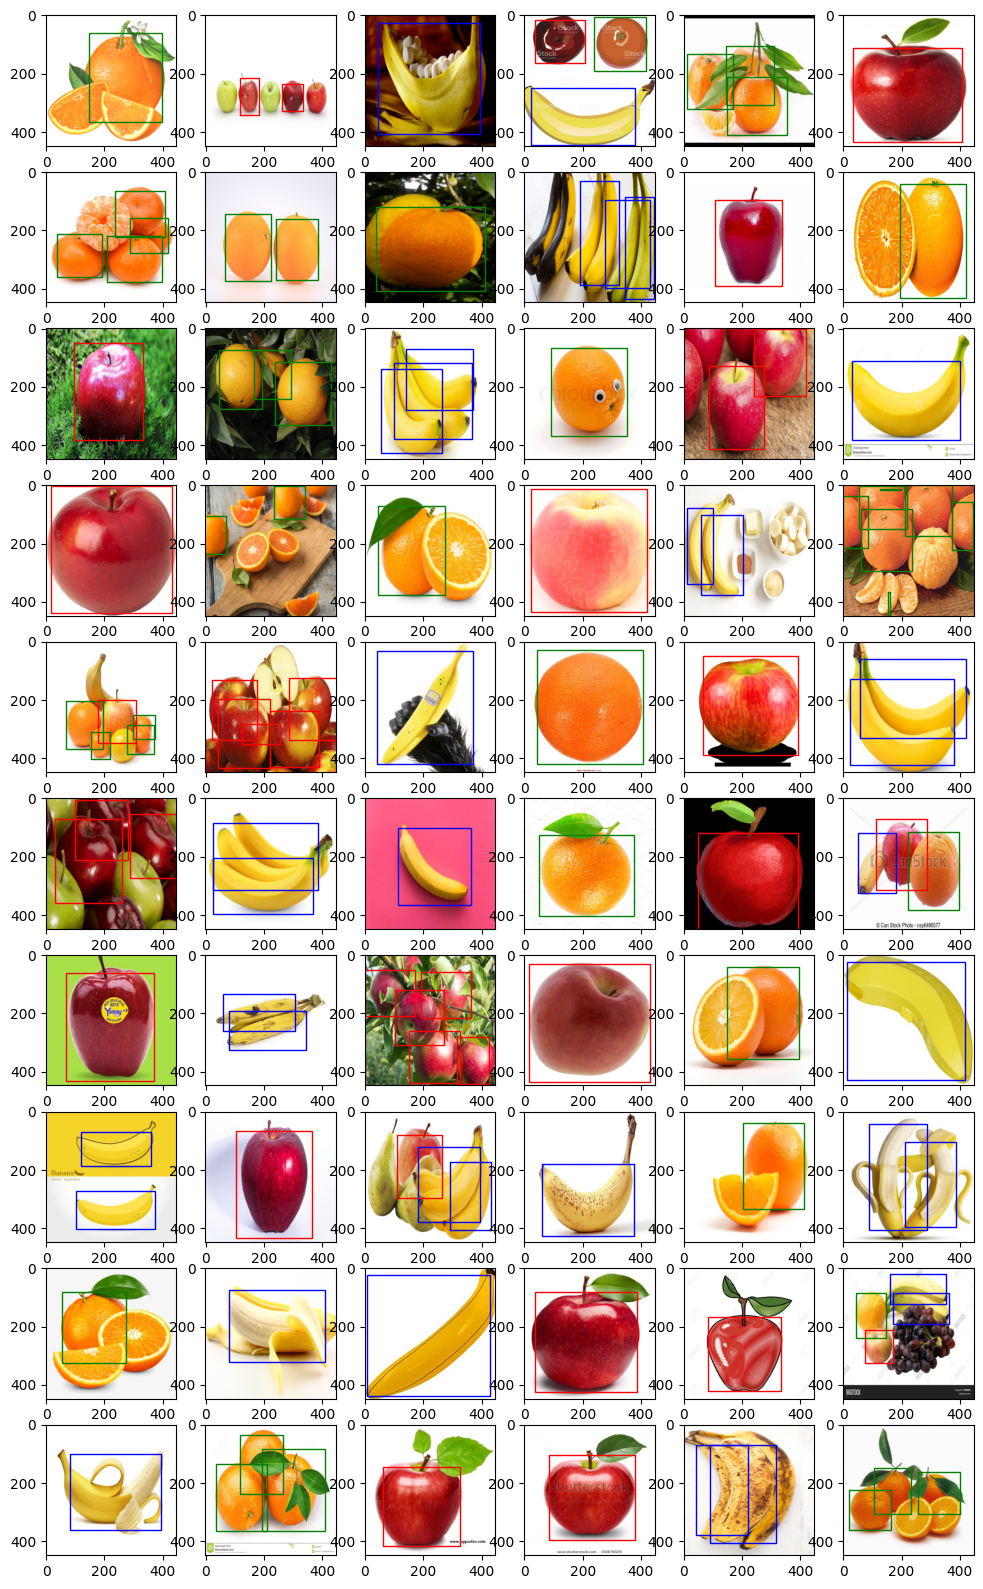

In [23]:
import matplotlib.pyplot as plt

color_classes = {
    0:'r',
    1:"b",
    2:"g"
}

fig, ax = plt.subplots(10, 6, figsize = (12, 20))
for idx, image in enumerate(images):
    ax[idx//6, idx%6].imshow(image.permute((1, 2, 0)).detach().numpy())
for box in preds:
    # Create a Rectangle patch
    box_rect = box.get('box')
    center_x = box_rect[0] - box_rect[2]/2
    center_y = box_rect[1] - box_rect[3]/2
    width = box_rect[2]
    height = box_rect[3]
    rect = patches.Rectangle((center_x * 448, center_y * 448), 
                             width * 448, height * 448, 
                             linewidth=1, 
                             edgecolor=color_classes.get(int(box.get("class"))), 
                             facecolor='none')
    idx_box = box.get("num_imag")
    # Add the patch to the Axes
    ax[idx_box//6, idx_box%6].add_patch(rect)